In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
from typing import Dict, Tuple
import os
from sklearn.linear_model import LinearRegression
import sys
import pyblock
bme_dir = '/projects/lindorff_group/people/thd711/HDX_project/code/BME/' # replace this with your local copy of the BME code
sys.path.append(bme_dir)
import BME as BME

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]

# --- Utility functions ---
def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))


outpath='./'
hyres_path = '../../IDP_REWEIGHTING/aSyn/rewM14DH_scaled/'
bioemu_path = '../../IDP_REWEIGHTING/aSyn/bioemu_M14DH_scaled/'
desres_path = '../../IDP_REWEIGHTING/aSyn/desres_M14DH_scaled/'
hyres_pf_path = '../../MD_DATA/aSyn/M14DH_scaled/'
bioemu_pf_path = '../../BIOEMU_IDPs/aSyn/M14DH_scaled/'
desres_pf_path = '../../DESRES_IDPs/aSyn/M14DH_scaled/'
ensembles = ['BioEmu', 'a99SB-disp', 'HyRes']
ensemble_paths = [bioemu_path, desres_path, hyres_path]

In [5]:
# load experimental data

df = pd.read_csv(f'../../EXP_DATA/aSyn.csv')
F_exp = np.array(df['Rel. Uptake'])
# ensure all experimental values are between 0 and 1
F_exp = np.maximum(F_exp, float(0))
F_exp = np.minimum(F_exp, float(1))
print(np.min(F_exp))
print(np.max(F_exp))
sigma = np.abs(np.array(df['Rel. Uptake SD']))
times = np.array(df['Time (s)'])
peptides = []
for i in range(len(df)):
    pep_i = [idx for idx in range(int(df['Start'][i]) - 1, int(df['End'][i]))] # 0-indexed
    peptides.append(pep_i)

0.0
1.0


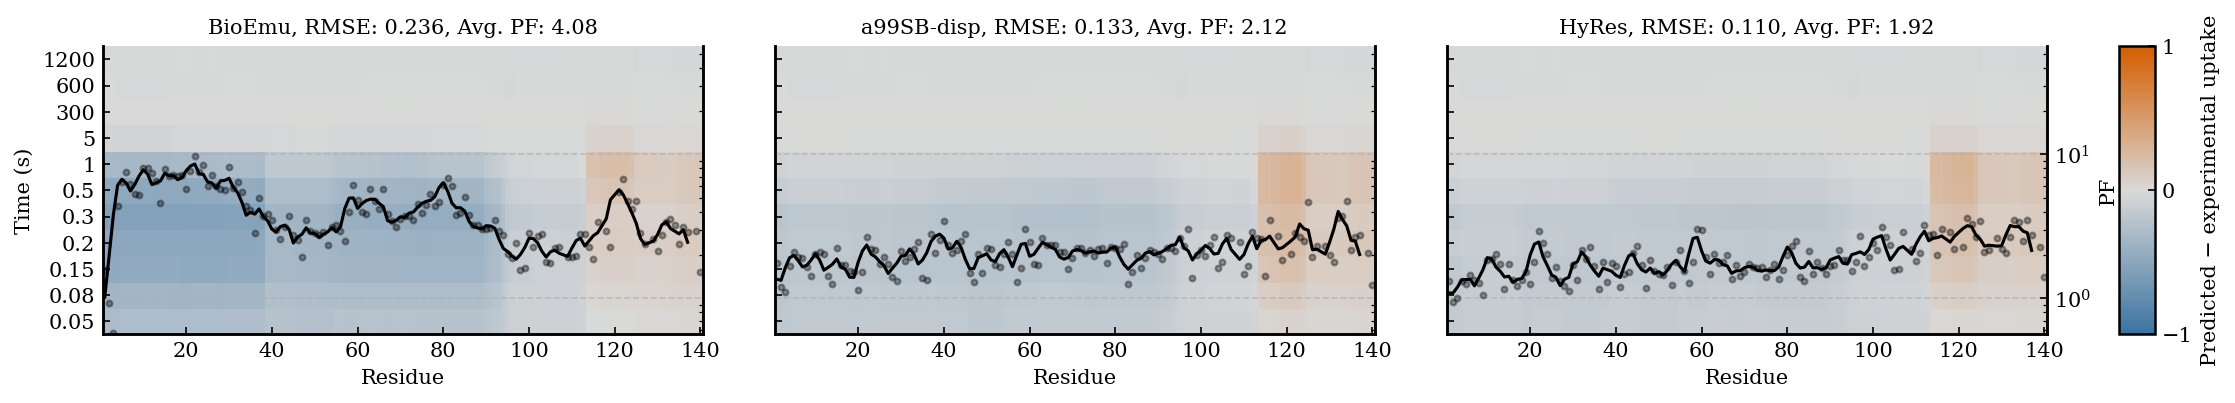

In [11]:

from matplotlib.colors import LinearSegmentedColormap

# comparison of HDX uptake differences + protection factors
protein = 'aSyn'
ensembles = ['BioEmu', 'a99SB-disp', 'HyRes']
ensemble_paths = [bioemu_path, desres_path, hyres_path]
pf_paths = [bioemu_pf_path, desres_pf_path, hyres_pf_path]  # paths to O.npy and amideresidues.txt
exp_uptake = pd.read_csv(f'../../EXP_DATA/{protein}.csv')

# load predicted uptakes and statistics
all_pred_values, all_rmse, all_chi2 = [], [], []
for ensemble, path in zip(ensembles, ensemble_paths):
    if ensemble == 'HyRes': rmse, chi2r, pred_vals = np.loadtxt(path + "rmse.txt")[0], np.loadtxt(path + "chi2r.txt")[0], np.load(path + "pred_uptakes.npy")[0]
    else: rmse, chi2r, pred_vals = np.loadtxt(path + "rmse.txt"), np.loadtxt(path + "chi2r.txt"), np.load(path + "pred_uptakes.npy")[0]
    all_pred_values.append(pred_vals); all_rmse.append(rmse); all_chi2.append(chi2r)

# load open/closed status and calculate PF = 1 / <f_open>
all_res, all_pf = [], []
for path in pf_paths:
    res, fopen = np.loadtxt(path + "amideresidues.txt").astype(int), np.load(path + "O.npy")
    PF = 1.0 / np.mean(fopen, axis=0)
    all_res.append(res); all_pf.append(PF)

# colour scale
cmap = LinearSegmentedColormap.from_list('difference_cmap', [(0.0, "#3B73A1"), (0.5, "#D9D9D9"), (1.0, "#D55E00")])

# residues and timepoints
times = np.sort(exp_uptake['Time (s)'].dropna().unique())
times_s = np.round(times, 2)
residues = np.arange(int(exp_uptake['Start'].min()), int(exp_uptake['End'].max()) + 1)
x_edges = np.arange(residues[0] - 0.5, residues[-1] + 1.5, 1)
y_edges = np.arange(len(times) + 1)

# build difference matrices
all_difference = []
for pred_vals in all_pred_values:
    df = exp_uptake.copy()
    df['Difference'] = pred_vals - df['Rel. Uptake']
    difference = np.full((len(times), len(residues)), np.nan)
    for i, t in enumerate(times):
        df_t = df[df['Time (s)'] == t]
        for j, resi in enumerate(residues):
            vals = df_t.loc[(df_t['Start'] <= resi) & (df_t['End'] >= resi), 'Difference'].values
            if len(vals) > 0: difference[i, j] = np.nanmean(vals)
    all_difference.append(difference)

# plot
fig, axes = plt.subplots(1, 3, figsize=(16, 3), sharex=True, sharey=True)
window_size = 3
kernel = np.ones(window_size) / window_size

for i, (ax, ensemble, difference, rmse, chi2, res, PF) in enumerate(zip(axes, ensembles, all_difference, all_rmse, all_chi2, all_res, all_pf)):
    im = ax.pcolormesh(x_edges, y_edges, difference, cmap=cmap, vmin=-1, vmax=1, shading='flat', rasterized=True)
    ax.set_title(f'{ensemble}, RMSE: {rmse:.3f}, Avg. PF: {np.mean(PF):.2f}', fontsize=10)
    ax.set_xlabel('Residue')
    ax.set_yticks(np.arange(len(times)) + 0.5)
    ax.set_yticklabels([f'{t:g}' for t in times_s])
    ax.tick_params(top=False, right=False)
    ax.spines['top'].set_visible(False)

    ax2 = ax.twinx()
    PF_smooth = np.convolve(PF, kernel, mode='valid')
    res_smooth = res[:len(PF_smooth)]
    ax2.scatter(res, PF, color='black', s=8, alpha=0.35, zorder=20)
    ax2.plot(res_smooth, PF_smooth, color='black', lw=1.5, zorder=21)
    ax2.set_yscale('log')
    ax2.set_ylim(10**-0.25, 10**1.75)
    ax2.tick_params(top=False)
    ax2.spines['top'].set_visible(False)

    if i == len(axes) - 1: ax2.set_ylabel('PF')
    else: ax2.set_yticklabels([]); ax2.tick_params(right=False)

axes[0].set_ylabel('Time (s)')

plt.subplots_adjust(left=0.08, right=0.89, bottom=0.18, top=0.82, wspace=0.12)
cax = fig.add_axes([0.92, 0.18, 0.015, 0.64])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Predicted − experimental uptake')
cbar.set_ticks([-1, 0, 1])

plt.savefig(f'{protein}_ensemble_uptake_difference_heatmaps_PF_M14DH_scaled.pdf', dpi=300, bbox_inches='tight')
plt.show()

In [12]:
hyres_pf_path = '../../MD_DATA/aSyn/M14DH/'
bioemu_pf_path = '../../BIOEMU_IDPs/aSyn/M14DH/'
desres_pf_path = '../../DESRES_IDPs/aSyn/M14DH/'
hyres_path = '../../IDP_REWEIGHTING/aSyn/rewM14DH/'
bioemu_path = '../../IDP_REWEIGHTING/aSyn/bioemu_M14DH/'
desres_path = '../../IDP_REWEIGHTING/aSyn/desres_M14DH/'

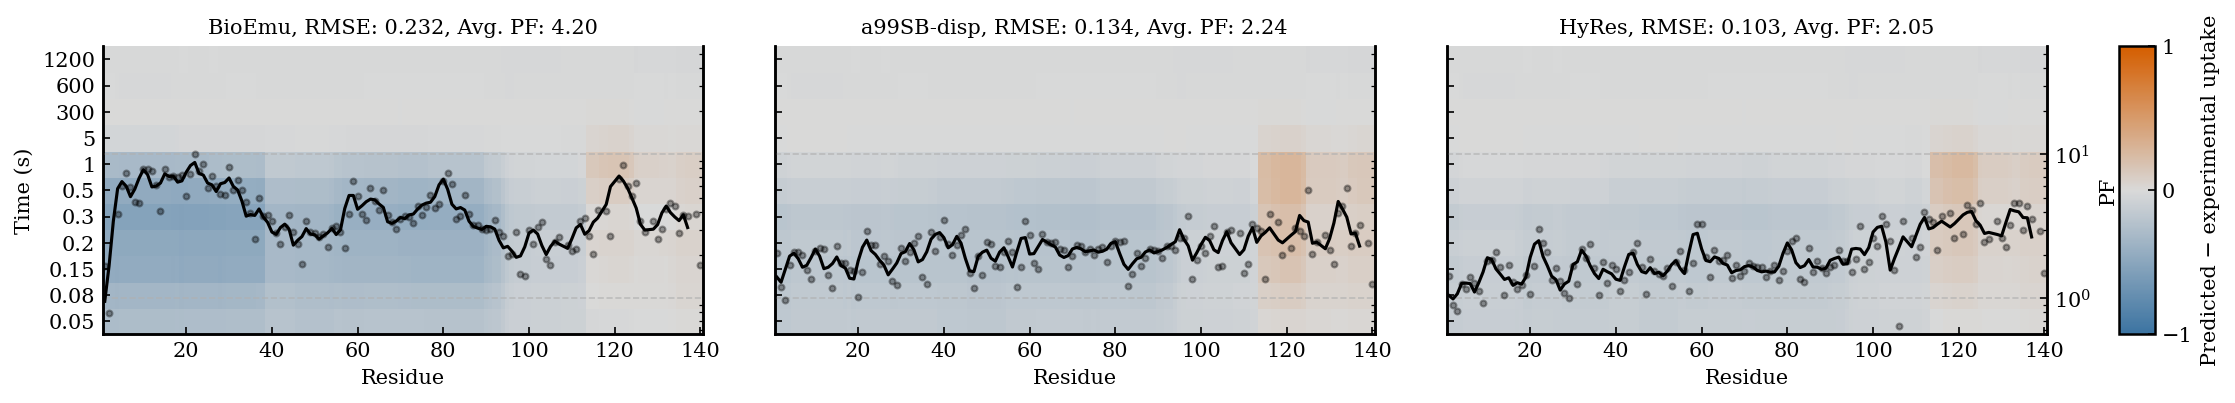

In [13]:

from matplotlib.colors import LinearSegmentedColormap

# comparison of HDX uptake differences + protection factors
protein = 'aSyn'
ensembles = ['BioEmu', 'a99SB-disp', 'HyRes']
ensemble_paths = [bioemu_path, desres_path, hyres_path]
pf_paths = [bioemu_pf_path, desres_pf_path, hyres_pf_path]  # paths to O.npy and amideresidues.txt
exp_uptake = pd.read_csv(f'../../EXP_DATA/{protein}.csv')

# load predicted uptakes and statistics
all_pred_values, all_rmse, all_chi2 = [], [], []
for ensemble, path in zip(ensembles, ensemble_paths):
    if ensemble == 'HyRes': rmse, chi2r, pred_vals = np.loadtxt(path + "rmse.txt")[0], np.loadtxt(path + "chi2r.txt")[0], np.load(path + "pred_uptakes.npy")[0]
    else: rmse, chi2r, pred_vals = np.loadtxt(path + "rmse.txt"), np.loadtxt(path + "chi2r.txt"), np.load(path + "pred_uptakes.npy")[0]
    all_pred_values.append(pred_vals); all_rmse.append(rmse); all_chi2.append(chi2r)

# load open/closed status and calculate PF = 1 / <f_open>
all_res, all_pf = [], []
for path in pf_paths:
    res, fopen = np.loadtxt(path + "amideresidues.txt").astype(int), np.load(path + "O.npy")
    PF = 1.0 / np.mean(fopen, axis=0)
    all_res.append(res); all_pf.append(PF)

# colour scale
cmap = LinearSegmentedColormap.from_list('difference_cmap', [(0.0, "#3B73A1"), (0.5, "#D9D9D9"), (1.0, "#D55E00")])

# residues and timepoints
times = np.sort(exp_uptake['Time (s)'].dropna().unique())
times_s = np.round(times, 2)
residues = np.arange(int(exp_uptake['Start'].min()), int(exp_uptake['End'].max()) + 1)
x_edges = np.arange(residues[0] - 0.5, residues[-1] + 1.5, 1)
y_edges = np.arange(len(times) + 1)

# build difference matrices
all_difference = []
for pred_vals in all_pred_values:
    df = exp_uptake.copy()
    df['Difference'] = pred_vals - df['Rel. Uptake']
    difference = np.full((len(times), len(residues)), np.nan)
    for i, t in enumerate(times):
        df_t = df[df['Time (s)'] == t]
        for j, resi in enumerate(residues):
            vals = df_t.loc[(df_t['Start'] <= resi) & (df_t['End'] >= resi), 'Difference'].values
            if len(vals) > 0: difference[i, j] = np.nanmean(vals)
    all_difference.append(difference)

# plot
fig, axes = plt.subplots(1, 3, figsize=(16, 3), sharex=True, sharey=True)
window_size = 3
kernel = np.ones(window_size) / window_size

for i, (ax, ensemble, difference, rmse, chi2, res, PF) in enumerate(zip(axes, ensembles, all_difference, all_rmse, all_chi2, all_res, all_pf)):
    im = ax.pcolormesh(x_edges, y_edges, difference, cmap=cmap, vmin=-1, vmax=1, shading='flat', rasterized=True)
    ax.set_title(f'{ensemble}, RMSE: {rmse:.3f}, Avg. PF: {np.mean(PF):.2f}', fontsize=10)
    ax.set_xlabel('Residue')
    ax.set_yticks(np.arange(len(times)) + 0.5)
    ax.set_yticklabels([f'{t:g}' for t in times_s])
    ax.tick_params(top=False, right=False)
    ax.spines['top'].set_visible(False)

    ax2 = ax.twinx()
    PF_smooth = np.convolve(PF, kernel, mode='valid')
    res_smooth = res[:len(PF_smooth)]
    ax2.scatter(res, PF, color='black', s=8, alpha=0.35, zorder=20)
    ax2.plot(res_smooth, PF_smooth, color='black', lw=1.5, zorder=21)
    ax2.set_yscale('log')
    ax2.set_ylim(10**-0.25, 10**1.75)
    ax2.tick_params(top=False)
    ax2.spines['top'].set_visible(False)

    if i == len(axes) - 1: ax2.set_ylabel('PF')
    else: ax2.set_yticklabels([]); ax2.tick_params(right=False)

axes[0].set_ylabel('Time (s)')

plt.subplots_adjust(left=0.08, right=0.89, bottom=0.18, top=0.82, wspace=0.12)
cax = fig.add_axes([0.92, 0.18, 0.015, 0.64])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Predicted − experimental uptake')
cbar.set_ticks([-1, 0, 1])

plt.savefig(f'{protein}_ensemble_uptake_difference_heatmaps_PF_M14DH.pdf', dpi=300, bbox_inches='tight')
plt.show()

In [14]:
hyres_pf_path = '../../MD_DATA/aSyn/M14/'
bioemu_pf_path = '../../BIOEMU_IDPs/aSyn/M14/'
desres_pf_path = '../../DESRES_IDPs/aSyn/M14/'
hyres_path = '../../IDP_REWEIGHTING/aSyn/rewM14/'
bioemu_path = '../../IDP_REWEIGHTING/aSyn/bioemu_M14/'
desres_path = '../../IDP_REWEIGHTING/aSyn/desres_M14/'

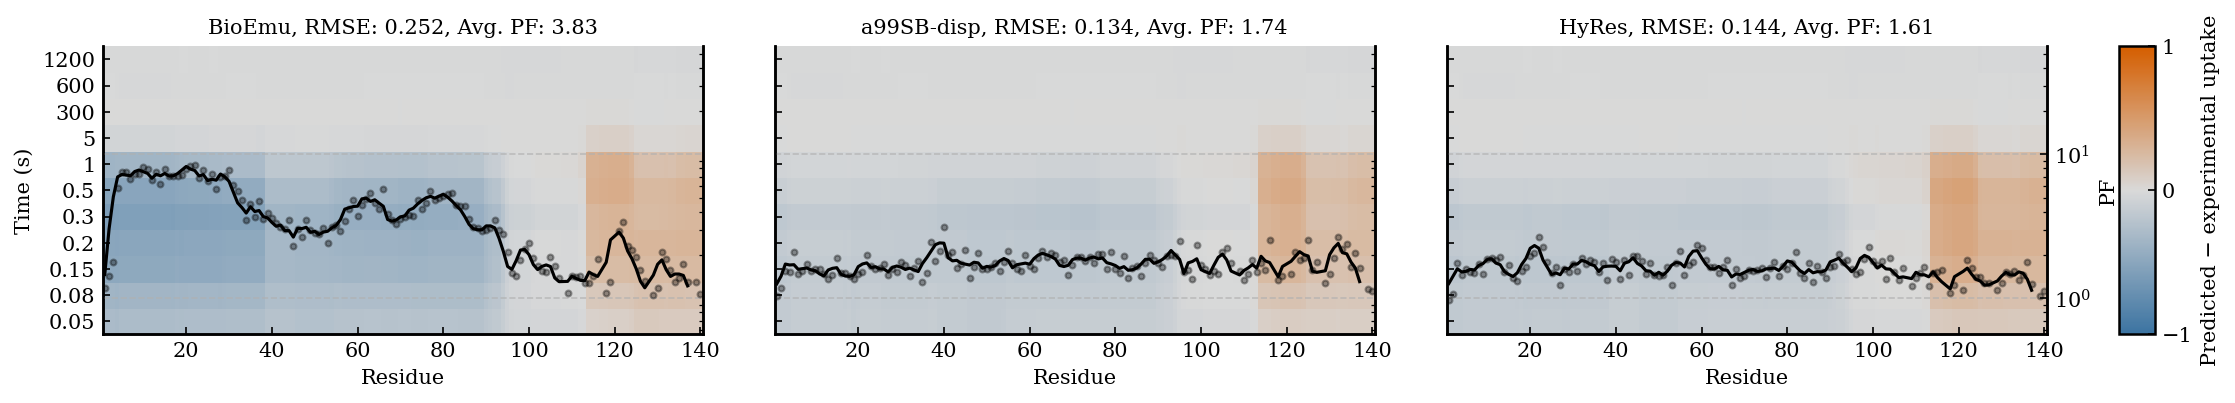

In [15]:

from matplotlib.colors import LinearSegmentedColormap

# comparison of HDX uptake differences + protection factors
protein = 'aSyn'
ensembles = ['BioEmu', 'a99SB-disp', 'HyRes']
ensemble_paths = [bioemu_path, desres_path, hyres_path]
pf_paths = [bioemu_pf_path, desres_pf_path, hyres_pf_path]  # paths to O.npy and amideresidues.txt
exp_uptake = pd.read_csv(f'../../EXP_DATA/{protein}.csv')

# load predicted uptakes and statistics
all_pred_values, all_rmse, all_chi2 = [], [], []
for ensemble, path in zip(ensembles, ensemble_paths):
    if ensemble == 'HyRes': rmse, chi2r, pred_vals = np.loadtxt(path + "rmse.txt")[0], np.loadtxt(path + "chi2r.txt")[0], np.load(path + "pred_uptakes.npy")[0]
    else: rmse, chi2r, pred_vals = np.loadtxt(path + "rmse.txt"), np.loadtxt(path + "chi2r.txt"), np.load(path + "pred_uptakes.npy")[0]
    all_pred_values.append(pred_vals); all_rmse.append(rmse); all_chi2.append(chi2r)

# load open/closed status and calculate PF = 1 / <f_open>
all_res, all_pf = [], []
for path in pf_paths:
    res, fopen = np.loadtxt(path + "amideresidues.txt").astype(int), np.load(path + "O.npy")
    PF = 1.0 / np.mean(fopen, axis=0)
    all_res.append(res); all_pf.append(PF)

# colour scale
cmap = LinearSegmentedColormap.from_list('difference_cmap', [(0.0, "#3B73A1"), (0.5, "#D9D9D9"), (1.0, "#D55E00")])

# residues and timepoints
times = np.sort(exp_uptake['Time (s)'].dropna().unique())
times_s = np.round(times, 2)
residues = np.arange(int(exp_uptake['Start'].min()), int(exp_uptake['End'].max()) + 1)
x_edges = np.arange(residues[0] - 0.5, residues[-1] + 1.5, 1)
y_edges = np.arange(len(times) + 1)

# build difference matrices
all_difference = []
for pred_vals in all_pred_values:
    df = exp_uptake.copy()
    df['Difference'] = pred_vals - df['Rel. Uptake']
    difference = np.full((len(times), len(residues)), np.nan)
    for i, t in enumerate(times):
        df_t = df[df['Time (s)'] == t]
        for j, resi in enumerate(residues):
            vals = df_t.loc[(df_t['Start'] <= resi) & (df_t['End'] >= resi), 'Difference'].values
            if len(vals) > 0: difference[i, j] = np.nanmean(vals)
    all_difference.append(difference)

# plot
fig, axes = plt.subplots(1, 3, figsize=(16, 3), sharex=True, sharey=True)
window_size = 3
kernel = np.ones(window_size) / window_size

for i, (ax, ensemble, difference, rmse, chi2, res, PF) in enumerate(zip(axes, ensembles, all_difference, all_rmse, all_chi2, all_res, all_pf)):
    im = ax.pcolormesh(x_edges, y_edges, difference, cmap=cmap, vmin=-1, vmax=1, shading='flat', rasterized=True)
    ax.set_title(f'{ensemble}, RMSE: {rmse:.3f}, Avg. PF: {np.mean(PF):.2f}', fontsize=10)
    ax.set_xlabel('Residue')
    ax.set_yticks(np.arange(len(times)) + 0.5)
    ax.set_yticklabels([f'{t:g}' for t in times_s])
    ax.tick_params(top=False, right=False)
    ax.spines['top'].set_visible(False)

    ax2 = ax.twinx()
    PF_smooth = np.convolve(PF, kernel, mode='valid')
    res_smooth = res[:len(PF_smooth)]
    ax2.scatter(res, PF, color='black', s=8, alpha=0.35, zorder=20)
    ax2.plot(res_smooth, PF_smooth, color='black', lw=1.5, zorder=21)
    ax2.set_yscale('log')
    ax2.set_ylim(10**-0.25, 10**1.75)
    ax2.tick_params(top=False)
    ax2.spines['top'].set_visible(False)

    if i == len(axes) - 1: ax2.set_ylabel('PF')
    else: ax2.set_yticklabels([]); ax2.tick_params(right=False)

axes[0].set_ylabel('Time (s)')

plt.subplots_adjust(left=0.08, right=0.89, bottom=0.18, top=0.82, wspace=0.12)
cax = fig.add_axes([0.92, 0.18, 0.015, 0.64])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Predicted − experimental uptake')
cbar.set_ticks([-1, 0, 1])

plt.savefig(f'{protein}_ensemble_uptake_difference_heatmaps_PF_M14.pdf', dpi=300, bbox_inches='tight')
plt.show()

In [16]:
# after reweighting M14DH_scaled BioEmu ensemble

In [17]:
# gather all the data

proteins = ['aSyn']

path = '../../BIOEMU_IDPs/'

ntrajs = 10

phi_threshold = 0.1

data = {}

for protein in proteins:
    data[protein] = {}

    phis = np.loadtxt(path+protein+"/HDXrew_M14DH_scaled/phis.txt")
    chi2r = np.loadtxt(path+protein+"/HDXrew_M14DH_scaled/chi2r.txt")
    rmse = np.loadtxt(path+protein+"/HDXrew_M14DH_scaled/rmse.txt")
    wopt_array = np.load(path+protein+"/HDXrew_M14DH_scaled/wopt_array.npy")
    pred_array = np.load(path+protein+"/HDXrew_M14DH_scaled/pred_uptakes.npy")

    stop_idx= np.where(phis<phi_threshold)[0][0]
    print(stop_idx)
    phis = phis[:stop_idx]
    chi2r = chi2r[:stop_idx]
    rmse = rmse[:stop_idx]
    wopt_array = wopt_array[:stop_idx]
    pred_array = pred_array[:stop_idx]

    data[protein]['phi'] = phis
    data[protein]['chi2r'] = chi2r
    data[protein]['rmse'] = rmse
    data[protein]['wopt_array'] = wopt_array
    data[protein]['pred_array'] = pred_array

        

print('done')


16
done


12


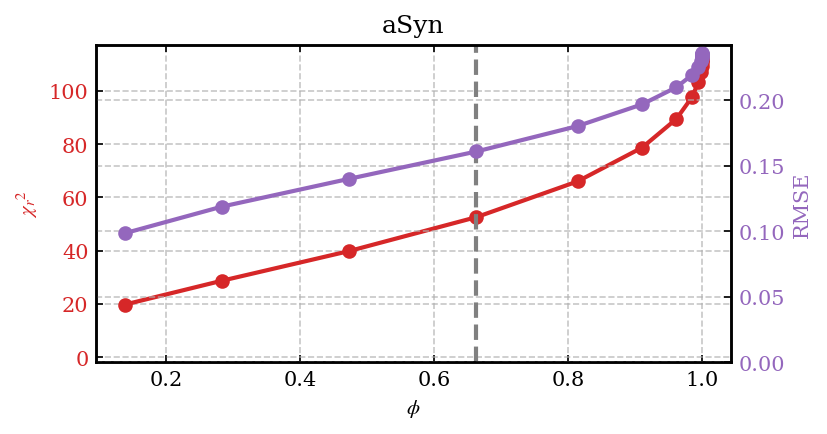

In [18]:
import math 
def find_elbow(x, y):
    # Convert to numpy arrays
    x = np.array(x)
    y = np.array(y)

    # Sort x (and y) if needed, but keep track of original indices
    if not np.all(np.diff(x) >= 0):
        idx_sort = np.argsort(x)
        x_sorted = x[idx_sort]
        y_sorted = y[idx_sort]
    else:
        idx_sort = np.arange(len(x))
        x_sorted, y_sorted = x, y

    # Line between first and last point
    p1 = np.array([x_sorted[0], y_sorted[0]])
    p2 = np.array([x_sorted[-1], y_sorted[-1]])
    line_vec = p2 - p1
    line_vec_norm = line_vec / np.linalg.norm(line_vec)

    # Distances from each point to the line
    vec_from_p1 = np.vstack([x_sorted - p1[0], y_sorted - p1[1]]).T
    proj_len = np.dot(vec_from_p1, line_vec_norm)
    proj_point = np.outer(proj_len, line_vec_norm) + p1
    dist = np.linalg.norm(vec_from_p1 - (proj_point - p1), axis=1)

    # Elbow = point with maximum distance
    idx_elbow_sorted = np.argmax(dist)
    idx_elbow_original = idx_sort[idx_elbow_sorted]

    return idx_elbow_original, x[idx_elbow_original], y[idx_elbow_original]

n_proteins = len(proteins)
ncols = 2
nrows = math.ceil(n_proteins / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(10, 3*nrows), sharex=False)

# Flatten axes array (works for any layout)
axes = np.array(axes).reshape(-1)

for ax, protein in zip(axes, proteins):
    phi = data[protein]['phi']
    chi2r = data[protein]['chi2r']
    rmse = data[protein]['rmse']

    # find elbow
    elidx, elx, ely = find_elbow(phi, rmse)
    elidx = elidx+1
    print(elidx)
    
    # Left axis
    ax.plot(phi, chi2r, 'o-', color='tab:red')
    ax.set_ylabel("$\chi$$_{r}$$^{2}$", color='tab:red')
    ax.tick_params(axis='y', labelcolor='tab:red')
    ax.axvline(phi[elidx], color = 'grey', linestyle='--')
    ax.set_title(protein)
    ax.set_xlabel("$\phi$")
    ax.set_ylim(-2,)
    
    # Right axis
    ax2 = ax.twinx()
    ax2.plot(phi, rmse, 'o-', color='tab:purple')
    ax2.set_ylabel("RMSE", color='tab:purple')
    ax2.tick_params(axis='y', labelcolor='tab:purple')
    ax2.set_ylim(0,)

# Hide unused subplots (if odd number of proteins)
for ax in axes[len(proteins):]:
    ax.set_visible(False)

plt.tight_layout()
plt.savefig('Lcurves_M14DH_scaled_BioEmu.pdf', dpi=200)


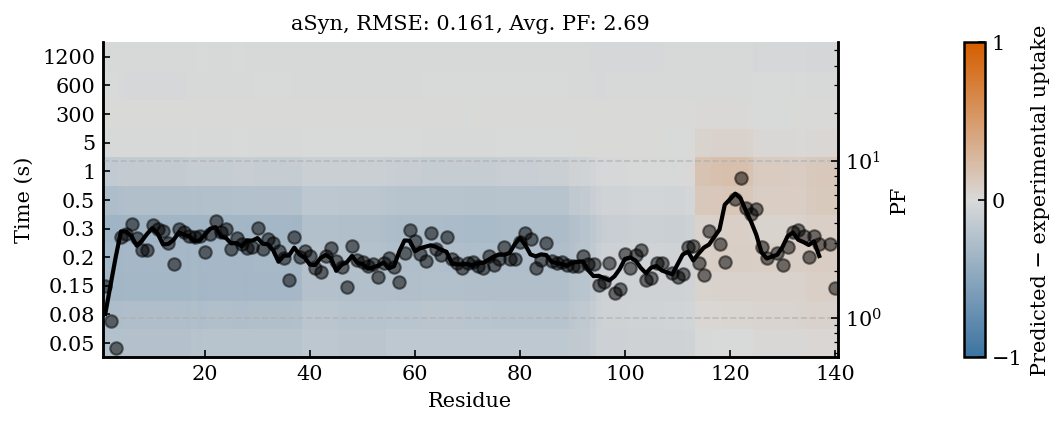

In [19]:
# plot posterior-experiment heatmap and PFs
from matplotlib.colors import LinearSegmentedColormap
protein = 'aSyn'

# ------------------------------------------------------------------
# Get posterior corresponding to automatically picked elbow
# ------------------------------------------------------------------

phi = data[protein]['phi']
rmse = data[protein]['rmse']
pred_array = np.array(data[protein]['pred_array'])

elidx, elx, ely = find_elbow(phi, rmse)
elidx = elidx + 1

# ------------------------------------------------------------------
# Experimental uptake + predicted - experimental difference
# pred_array is assumed to be in the same row order as the CSV
# ------------------------------------------------------------------

exp_uptake = pd.read_csv(f'../../EXP_DATA/{protein}.csv')
exp_uptake['Difference'] = pred_array[elidx] - exp_uptake['Rel. Uptake']

# colour scale: -1 -> 0 -> +1
cmap = LinearSegmentedColormap.from_list('difference_cmap', [(0.0, "#3B73A1"), (0.5, "#D9D9D9"), (1.0, "#D55E00")])

# ------------------------------------------------------------------
# Build residue x time matrix
# Each peptide contributes its predicted - experimental difference
# to every residue it covers.
# Overlapping peptides are averaged at each residue/time point.
# ------------------------------------------------------------------

times = np.sort(exp_uptake['Time (s)'].dropna().unique())
times_min = np.round(times / 60, 1)
residues = np.arange(int(exp_uptake['Start'].min()), int(exp_uptake['End'].max()) + 1)

difference = np.full((len(times), len(residues)), np.nan)

for i, t in enumerate(times):
    df_t = exp_uptake[exp_uptake['Time (s)'] == t]
    for j, resi in enumerate(residues):
        vals = df_t.loc[(df_t['Start'] <= resi) & (df_t['End'] >= resi), 'Difference'].values
        if len(vals) > 0:
            difference[i, j] = np.nanmean(vals)

# ------------------------------------------------------------------
# Calculate posterior ensemble-averaged protection factors
# ------------------------------------------------------------------

res = np.loadtxt(f'../../BIOEMU_IDPs/{protein}/M14DH_scaled/amideresidues.txt').astype(int)
fopen = np.load(f'../../BIOEMU_IDPs/{protein}/M14DH_scaled/O.npy')

synframes = 0
wopt = data[protein]['wopt_array'][elidx]

PF_post = 1 / np.average(fopen, axis=0, weights=wopt[:len(wopt)-synframes])

# moving average
window_size = 3
kernel = np.ones(window_size) / window_size
PF_post_smooth = np.convolve(PF_post, kernel, mode='valid')
res_smooth = res[:len(PF_post_smooth)]

# ------------------------------------------------------------------
# Cell edges for pcolormesh
# ------------------------------------------------------------------

x_edges = np.arange(residues[0] - 0.5, residues[-1] + 1.5, 1)
y_edges = np.arange(len(times) + 1)

# ------------------------------------------------------------------
# Plot
# Keep heatmap itself the same width as in the original heatmap
# ------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 3))

im = ax.pcolormesh(x_edges, y_edges, difference, cmap=cmap, vmin=-1, vmax=1, shading='flat', rasterized=True)

ax.set_xlabel('Residue')
ax.set_ylabel('Time (s)')
ax.set_title(protein + str(f', RMSE: {rmse[elidx]:.3f}, Avg. PF: {np.mean(PF_post):.2f}'), fontsize=10)

ax.set_yticks(np.arange(len(times)) + 0.5)
ax.set_yticklabels([f'{t:g}' for t in times_s])

ax.tick_params(top=False, right=False)
ax.spines['top'].set_visible(False)

# ------------------------------------------------------------------
# Protection factors on right y-axis
# ------------------------------------------------------------------

ax2 = ax.twinx()

ax2.scatter(res, PF_post, color='black', alpha=0.5, zorder=20)
ax2.plot(res_smooth, PF_post_smooth, color='black', lw=2, zorder=21)

ax2.set_ylabel('PF')
ax2.set_yscale('log')
ax2.set_ylim(10**-0.25, 10**1.75)
ax2.tick_params(top=False)
ax2.spines['top'].set_visible(False)

# ------------------------------------------------------------------
# Match original heatmap plotting width and add colorbar outside it
# ------------------------------------------------------------------

plt.subplots_adjust(left=0.12, right=0.82, bottom=0.18, top=0.88)

cax = fig.add_axes([0.94, 0.18, 0.02, 0.70])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Predicted − experimental uptake')
cbar.set_ticks([-1, 0, 1])

plt.savefig(f'{protein}_BioEmu_uptake_difference_heatmap_PF_post1.pdf', dpi=300, bbox_inches='tight')
plt.show()

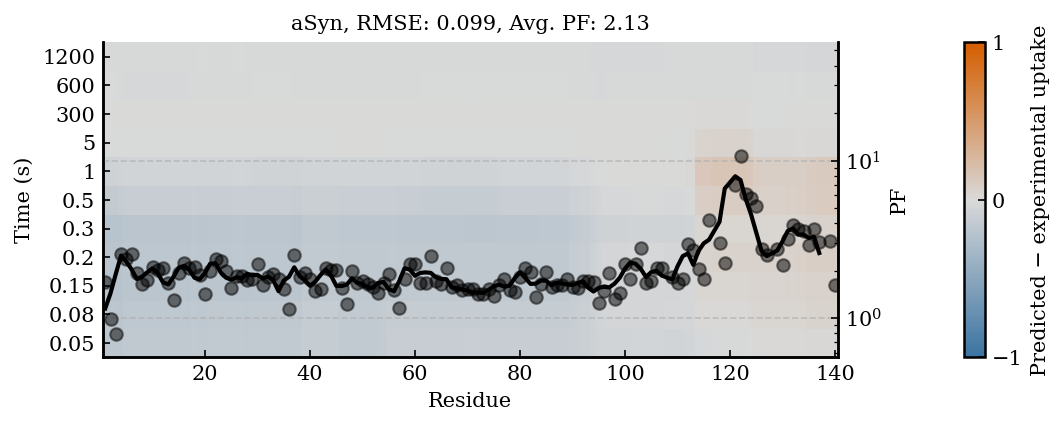

In [21]:
# plot posterior-experiment heatmap and PFs
from matplotlib.colors import LinearSegmentedColormap
protein = 'aSyn'

# ------------------------------------------------------------------
# Get posterior corresponding to automatically picked elbow
# ------------------------------------------------------------------

phi = data[protein]['phi']
rmse = data[protein]['rmse']
pred_array = np.array(data[protein]['pred_array'])


elidx = -1 # posterior 2

# ------------------------------------------------------------------
# Experimental uptake + predicted - experimental difference
# pred_array is assumed to be in the same row order as the CSV
# ------------------------------------------------------------------

exp_uptake = pd.read_csv(f'../../EXP_DATA/{protein}.csv')
exp_uptake['Difference'] = pred_array[elidx] - exp_uptake['Rel. Uptake']

# colour scale: -1 -> 0 -> +1
cmap = LinearSegmentedColormap.from_list('difference_cmap', [(0.0, "#3B73A1"), (0.5, "#D9D9D9"), (1.0, "#D55E00")])

# ------------------------------------------------------------------
# Build residue x time matrix
# Each peptide contributes its predicted - experimental difference
# to every residue it covers.
# Overlapping peptides are averaged at each residue/time point.
# ------------------------------------------------------------------

times = np.sort(exp_uptake['Time (s)'].dropna().unique())
times_min = np.round(times / 60, 1)
residues = np.arange(int(exp_uptake['Start'].min()), int(exp_uptake['End'].max()) + 1)

difference = np.full((len(times), len(residues)), np.nan)

for i, t in enumerate(times):
    df_t = exp_uptake[exp_uptake['Time (s)'] == t]
    for j, resi in enumerate(residues):
        vals = df_t.loc[(df_t['Start'] <= resi) & (df_t['End'] >= resi), 'Difference'].values
        if len(vals) > 0:
            difference[i, j] = np.nanmean(vals)

# ------------------------------------------------------------------
# Calculate posterior ensemble-averaged protection factors
# ------------------------------------------------------------------

res = np.loadtxt(f'../../BIOEMU_IDPs/{protein}/M14DH_scaled/amideresidues.txt').astype(int)
fopen = np.load(f'../../BIOEMU_IDPs/{protein}/M14DH_scaled/O.npy')

synframes = 0
wopt = data[protein]['wopt_array'][elidx]

PF_post = 1 / np.average(fopen, axis=0, weights=wopt[:len(wopt)-synframes])

# moving average
window_size = 3
kernel = np.ones(window_size) / window_size
PF_post_smooth = np.convolve(PF_post, kernel, mode='valid')
res_smooth = res[:len(PF_post_smooth)]

# ------------------------------------------------------------------
# Cell edges for pcolormesh
# ------------------------------------------------------------------

x_edges = np.arange(residues[0] - 0.5, residues[-1] + 1.5, 1)
y_edges = np.arange(len(times) + 1)

# ------------------------------------------------------------------
# Plot
# Keep heatmap itself the same width as in the original heatmap
# ------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 3))

im = ax.pcolormesh(x_edges, y_edges, difference, cmap=cmap, vmin=-1, vmax=1, shading='flat', rasterized=True)

ax.set_xlabel('Residue')
ax.set_ylabel('Time (s)')
ax.set_title(protein + str(f', RMSE: {rmse[elidx]:.3f}, Avg. PF: {np.mean(PF_post):.2f}'), fontsize=10)

ax.set_yticks(np.arange(len(times)) + 0.5)
ax.set_yticklabels([f'{t:g}' for t in times_s])

ax.tick_params(top=False, right=False)
ax.spines['top'].set_visible(False)

# ------------------------------------------------------------------
# Protection factors on right y-axis
# ------------------------------------------------------------------

ax2 = ax.twinx()

ax2.scatter(res, PF_post, color='black', alpha=0.5, zorder=20)
ax2.plot(res_smooth, PF_post_smooth, color='black', lw=2, zorder=21)

ax2.set_ylabel('PF')
ax2.set_yscale('log')
ax2.set_ylim(10**-0.25, 10**1.75)
ax2.tick_params(top=False)
ax2.spines['top'].set_visible(False)

# ------------------------------------------------------------------
# Match original heatmap plotting width and add colorbar outside it
# ------------------------------------------------------------------

plt.subplots_adjust(left=0.12, right=0.82, bottom=0.18, top=0.88)

cax = fig.add_axes([0.94, 0.18, 0.02, 0.70])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Predicted − experimental uptake')
cbar.set_ticks([-1, 0, 1])

plt.savefig(f'{protein}_BioEmu_uptake_difference_heatmap_PF_post2.pdf', dpi=300, bbox_inches='tight')
plt.show()

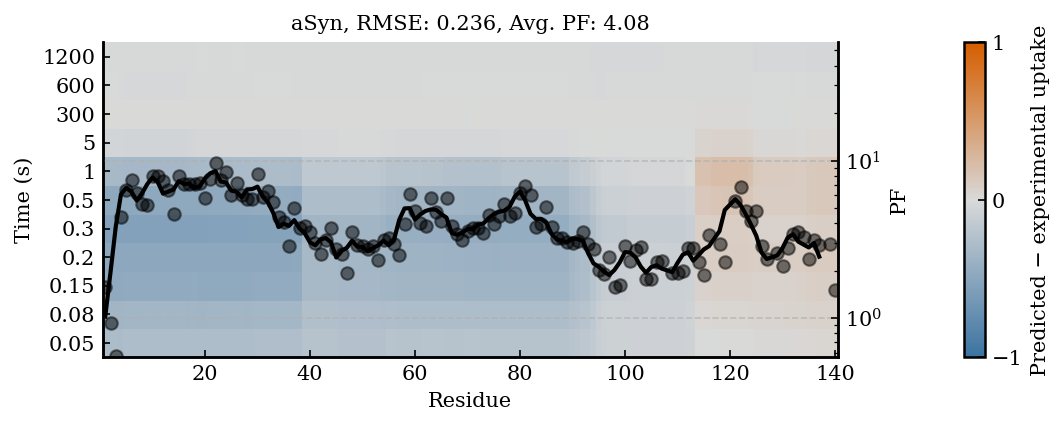

In [22]:
# plot posterior-experiment heatmap and PFs
from matplotlib.colors import LinearSegmentedColormap
protein = 'aSyn'

# ------------------------------------------------------------------
# Get posterior corresponding to automatically picked elbow
# ------------------------------------------------------------------

phi = data[protein]['phi']
rmse = data[protein]['rmse']
pred_array = np.array(data[protein]['pred_array'])


elidx = 0 # prior

# ------------------------------------------------------------------
# Experimental uptake + predicted - experimental difference
# pred_array is assumed to be in the same row order as the CSV
# ------------------------------------------------------------------

exp_uptake = pd.read_csv(f'../../EXP_DATA/{protein}.csv')
exp_uptake['Difference'] = pred_array[elidx] - exp_uptake['Rel. Uptake']

# colour scale: -1 -> 0 -> +1
cmap = LinearSegmentedColormap.from_list('difference_cmap', [(0.0, "#3B73A1"), (0.5, "#D9D9D9"), (1.0, "#D55E00")])

# ------------------------------------------------------------------
# Build residue x time matrix
# Each peptide contributes its predicted - experimental difference
# to every residue it covers.
# Overlapping peptides are averaged at each residue/time point.
# ------------------------------------------------------------------

times = np.sort(exp_uptake['Time (s)'].dropna().unique())
times_min = np.round(times / 60, 1)
residues = np.arange(int(exp_uptake['Start'].min()), int(exp_uptake['End'].max()) + 1)

difference = np.full((len(times), len(residues)), np.nan)

for i, t in enumerate(times):
    df_t = exp_uptake[exp_uptake['Time (s)'] == t]
    for j, resi in enumerate(residues):
        vals = df_t.loc[(df_t['Start'] <= resi) & (df_t['End'] >= resi), 'Difference'].values
        if len(vals) > 0:
            difference[i, j] = np.nanmean(vals)

# ------------------------------------------------------------------
# Calculate posterior ensemble-averaged protection factors
# ------------------------------------------------------------------

res = np.loadtxt(f'../../BIOEMU_IDPs/{protein}/M14DH_scaled/amideresidues.txt').astype(int)
fopen = np.load(f'../../BIOEMU_IDPs/{protein}/M14DH_scaled/O.npy')

synframes = 0
wopt = data[protein]['wopt_array'][elidx]

PF_post = 1 / np.average(fopen, axis=0, weights=wopt[:len(wopt)-synframes])

# moving average
window_size = 3
kernel = np.ones(window_size) / window_size
PF_post_smooth = np.convolve(PF_post, kernel, mode='valid')
res_smooth = res[:len(PF_post_smooth)]

# ------------------------------------------------------------------
# Cell edges for pcolormesh
# ------------------------------------------------------------------

x_edges = np.arange(residues[0] - 0.5, residues[-1] + 1.5, 1)
y_edges = np.arange(len(times) + 1)

# ------------------------------------------------------------------
# Plot
# Keep heatmap itself the same width as in the original heatmap
# ------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 3))

im = ax.pcolormesh(x_edges, y_edges, difference, cmap=cmap, vmin=-1, vmax=1, shading='flat', rasterized=True)

ax.set_xlabel('Residue')
ax.set_ylabel('Time (s)')
ax.set_title(protein + str(f', RMSE: {rmse[elidx]:.3f}, Avg. PF: {np.mean(PF_post):.2f}'), fontsize=10)

ax.set_yticks(np.arange(len(times)) + 0.5)
ax.set_yticklabels([f'{t:g}' for t in times_s])

ax.tick_params(top=False, right=False)
ax.spines['top'].set_visible(False)

# ------------------------------------------------------------------
# Protection factors on right y-axis
# ------------------------------------------------------------------

ax2 = ax.twinx()

ax2.scatter(res, PF_post, color='black', alpha=0.5, zorder=20)
ax2.plot(res_smooth, PF_post_smooth, color='black', lw=2, zorder=21)

ax2.set_ylabel('PF')
ax2.set_yscale('log')
ax2.set_ylim(10**-0.25, 10**1.75)
ax2.tick_params(top=False)
ax2.spines['top'].set_visible(False)

# ------------------------------------------------------------------
# Match original heatmap plotting width and add colorbar outside it
# ------------------------------------------------------------------

plt.subplots_adjust(left=0.12, right=0.82, bottom=0.18, top=0.88)

cax = fig.add_axes([0.94, 0.18, 0.02, 0.70])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Predicted − experimental uptake')
cbar.set_ticks([-1, 0, 1])

plt.savefig(f'{protein}_BioEmu_uptake_difference_heatmap_PF_prior.pdf', dpi=300, bbox_inches='tight')
plt.show()

In [23]:
# DESRES reweighting
# gather all the data

proteins = ['aSyn']

path = '../../DESRES_IDPs/'

ntrajs = 10

phi_threshold = 0.1

data = {}

for protein in proteins:
    data[protein] = {}

    phis = np.loadtxt(path+protein+"/HDXrew_M14DH_scaled/phis.txt")
    chi2r = np.loadtxt(path+protein+"/HDXrew_M14DH_scaled/chi2r.txt")
    rmse = np.loadtxt(path+protein+"/HDXrew_M14DH_scaled/rmse.txt")
    wopt_array = np.load(path+protein+"/HDXrew_M14DH_scaled/wopt_array.npy")
    pred_array = np.load(path+protein+"/HDXrew_M14DH_scaled/pred_uptakes.npy")

    stop_idx= np.where(phis<phi_threshold)[0][0]
    print(stop_idx)
    phis = phis[:stop_idx]
    chi2r = chi2r[:stop_idx]
    rmse = rmse[:stop_idx]
    wopt_array = wopt_array[:stop_idx]
    pred_array = pred_array[:stop_idx]

    data[protein]['phi'] = phis
    data[protein]['chi2r'] = chi2r
    data[protein]['rmse'] = rmse
    data[protein]['wopt_array'] = wopt_array
    data[protein]['pred_array'] = pred_array

        

print('done')


17
done


14


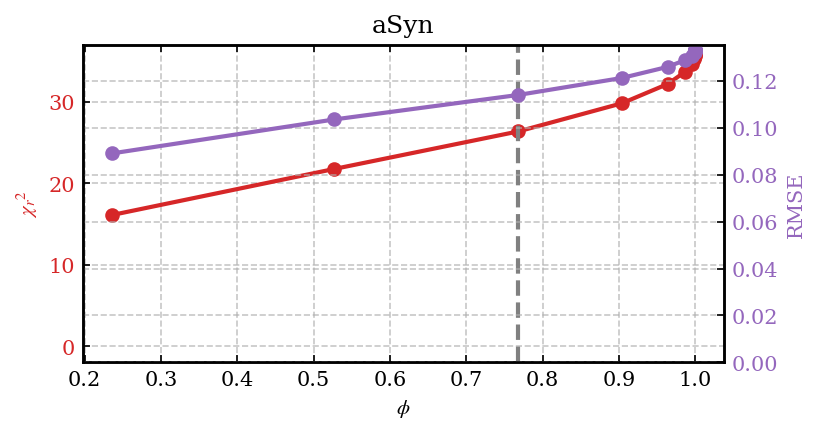

In [24]:
import math 
def find_elbow(x, y):
    # Convert to numpy arrays
    x = np.array(x)
    y = np.array(y)

    # Sort x (and y) if needed, but keep track of original indices
    if not np.all(np.diff(x) >= 0):
        idx_sort = np.argsort(x)
        x_sorted = x[idx_sort]
        y_sorted = y[idx_sort]
    else:
        idx_sort = np.arange(len(x))
        x_sorted, y_sorted = x, y

    # Line between first and last point
    p1 = np.array([x_sorted[0], y_sorted[0]])
    p2 = np.array([x_sorted[-1], y_sorted[-1]])
    line_vec = p2 - p1
    line_vec_norm = line_vec / np.linalg.norm(line_vec)

    # Distances from each point to the line
    vec_from_p1 = np.vstack([x_sorted - p1[0], y_sorted - p1[1]]).T
    proj_len = np.dot(vec_from_p1, line_vec_norm)
    proj_point = np.outer(proj_len, line_vec_norm) + p1
    dist = np.linalg.norm(vec_from_p1 - (proj_point - p1), axis=1)

    # Elbow = point with maximum distance
    idx_elbow_sorted = np.argmax(dist)
    idx_elbow_original = idx_sort[idx_elbow_sorted]

    return idx_elbow_original, x[idx_elbow_original], y[idx_elbow_original]

n_proteins = len(proteins)
ncols = 2
nrows = math.ceil(n_proteins / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(10, 3*nrows), sharex=False)

# Flatten axes array (works for any layout)
axes = np.array(axes).reshape(-1)

for ax, protein in zip(axes, proteins):
    phi = data[protein]['phi']
    chi2r = data[protein]['chi2r']
    rmse = data[protein]['rmse']

    # find elbow
    elidx, elx, ely = find_elbow(phi, rmse)
    elidx = elidx+1
    print(elidx)
    
    # Left axis
    ax.plot(phi, chi2r, 'o-', color='tab:red')
    ax.set_ylabel("$\chi$$_{r}$$^{2}$", color='tab:red')
    ax.tick_params(axis='y', labelcolor='tab:red')
    ax.axvline(phi[elidx], color = 'grey', linestyle='--')
    ax.set_title(protein)
    ax.set_xlabel("$\phi$")
    ax.set_ylim(-2,)
    
    # Right axis
    ax2 = ax.twinx()
    ax2.plot(phi, rmse, 'o-', color='tab:purple')
    ax2.set_ylabel("RMSE", color='tab:purple')
    ax2.tick_params(axis='y', labelcolor='tab:purple')
    ax2.set_ylim(0,)

# Hide unused subplots (if odd number of proteins)
for ax in axes[len(proteins):]:
    ax.set_visible(False)

plt.tight_layout()
plt.savefig('Lcurves_M14DH_scaled_DESRES.pdf', dpi=200)


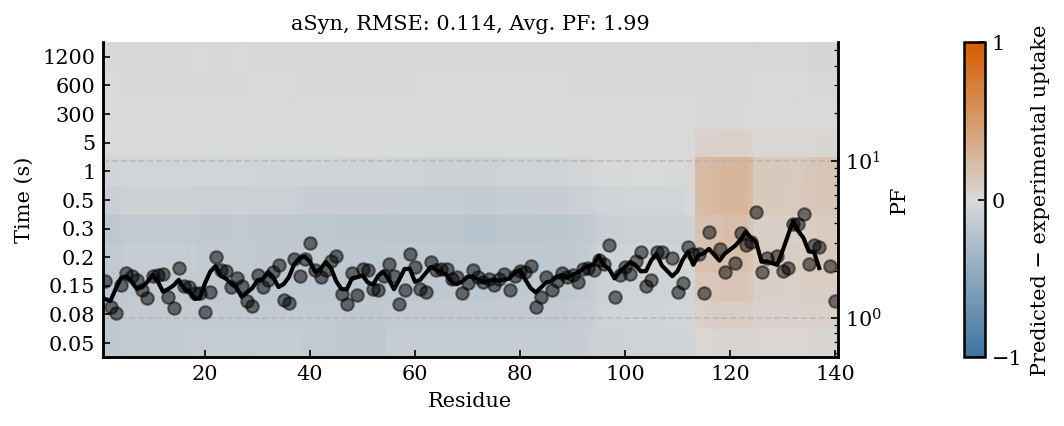

In [25]:
# plot posterior-experiment heatmap and PFs
from matplotlib.colors import LinearSegmentedColormap
protein = 'aSyn'

# ------------------------------------------------------------------
# Get posterior corresponding to automatically picked elbow
# ------------------------------------------------------------------

phi = data[protein]['phi']
rmse = data[protein]['rmse']
pred_array = np.array(data[protein]['pred_array'])

elidx, elx, ely = find_elbow(phi, rmse)
elidx = elidx + 1

# ------------------------------------------------------------------
# Experimental uptake + predicted - experimental difference
# pred_array is assumed to be in the same row order as the CSV
# ------------------------------------------------------------------

exp_uptake = pd.read_csv(f'../../EXP_DATA/{protein}.csv')
exp_uptake['Difference'] = pred_array[elidx] - exp_uptake['Rel. Uptake']

# colour scale: -1 -> 0 -> +1
cmap = LinearSegmentedColormap.from_list('difference_cmap', [(0.0, "#3B73A1"), (0.5, "#D9D9D9"), (1.0, "#D55E00")])

# ------------------------------------------------------------------
# Build residue x time matrix
# Each peptide contributes its predicted - experimental difference
# to every residue it covers.
# Overlapping peptides are averaged at each residue/time point.
# ------------------------------------------------------------------

times_s = np.sort(exp_uptake['Time (s)'].dropna().unique())
residues = np.arange(int(exp_uptake['Start'].min()), int(exp_uptake['End'].max()) + 1)

difference = np.full((len(times), len(residues)), np.nan)

for i, t in enumerate(times):
    df_t = exp_uptake[exp_uptake['Time (s)'] == t]
    for j, resi in enumerate(residues):
        vals = df_t.loc[(df_t['Start'] <= resi) & (df_t['End'] >= resi), 'Difference'].values
        if len(vals) > 0:
            difference[i, j] = np.nanmean(vals)

# ------------------------------------------------------------------
# Calculate posterior ensemble-averaged protection factors
# ------------------------------------------------------------------

res = np.loadtxt(f'../../DESRES_IDPs/{protein}/M14DH_scaled/amideresidues.txt').astype(int)
fopen = np.load(f'../../DESRES_IDPs/{protein}/M14DH_scaled/O.npy')

synframes = 0
wopt = data[protein]['wopt_array'][elidx]

PF_post = 1 / np.average(fopen, axis=0, weights=wopt[:len(wopt)-synframes])

# moving average
window_size = 3
kernel = np.ones(window_size) / window_size
PF_post_smooth = np.convolve(PF_post, kernel, mode='valid')
res_smooth = res[:len(PF_post_smooth)]

# ------------------------------------------------------------------
# Cell edges for pcolormesh
# ------------------------------------------------------------------

x_edges = np.arange(residues[0] - 0.5, residues[-1] + 1.5, 1)
y_edges = np.arange(len(times) + 1)

# ------------------------------------------------------------------
# Plot
# Keep heatmap itself the same width as in the original heatmap
# ------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 3))

im = ax.pcolormesh(x_edges, y_edges, difference, cmap=cmap, vmin=-1, vmax=1, shading='flat', rasterized=True)

ax.set_xlabel('Residue')
ax.set_ylabel('Time (s)')
ax.set_title(protein + str(f', RMSE: {rmse[elidx]:.3f}, Avg. PF: {np.mean(PF_post):.2f}'), fontsize=10)

ax.set_yticks(np.arange(len(times)) + 0.5)
ax.set_yticklabels([f'{t:g}' for t in times_s])

ax.tick_params(top=False, right=False)
ax.spines['top'].set_visible(False)

# ------------------------------------------------------------------
# Protection factors on right y-axis
# ------------------------------------------------------------------

ax2 = ax.twinx()

ax2.scatter(res, PF_post, color='black', alpha=0.5, zorder=20)
ax2.plot(res_smooth, PF_post_smooth, color='black', lw=2, zorder=21)

ax2.set_ylabel('PF')
ax2.set_yscale('log')
ax2.set_ylim(10**-0.25, 10**1.75)
ax2.tick_params(top=False)
ax2.spines['top'].set_visible(False)

# ------------------------------------------------------------------
# Match original heatmap plotting width and add colorbar outside it
# ------------------------------------------------------------------

plt.subplots_adjust(left=0.12, right=0.82, bottom=0.18, top=0.88)

cax = fig.add_axes([0.94, 0.18, 0.02, 0.70])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Predicted − experimental uptake')
cbar.set_ticks([-1, 0, 1])

plt.savefig(f'{protein}_DESRES_uptake_difference_heatmap_PF_post1.pdf', dpi=300, bbox_inches='tight')
plt.show()

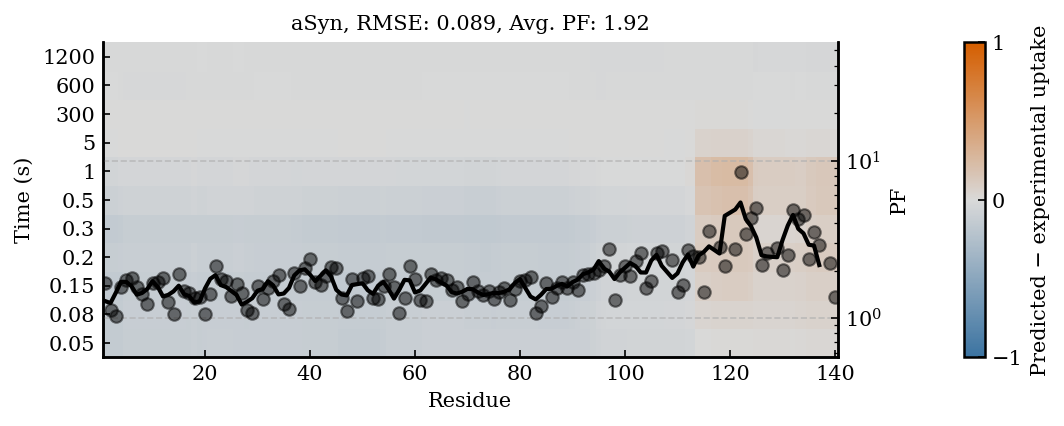

In [26]:
# plot posterior-experiment heatmap and PFs
from matplotlib.colors import LinearSegmentedColormap
protein = 'aSyn'

# ------------------------------------------------------------------
# Get posterior corresponding to automatically picked elbow
# ------------------------------------------------------------------

phi = data[protein]['phi']
rmse = data[protein]['rmse']
pred_array = np.array(data[protein]['pred_array'])

elidx = -1 # posterior 2

# ------------------------------------------------------------------
# Experimental uptake + predicted - experimental difference
# pred_array is assumed to be in the same row order as the CSV
# ------------------------------------------------------------------

exp_uptake = pd.read_csv(f'../../EXP_DATA/{protein}.csv')
exp_uptake['Difference'] = pred_array[elidx] - exp_uptake['Rel. Uptake']

# colour scale: -1 -> 0 -> +1
cmap = LinearSegmentedColormap.from_list('difference_cmap', [(0.0, "#3B73A1"), (0.5, "#D9D9D9"), (1.0, "#D55E00")])

# ------------------------------------------------------------------
# Build residue x time matrix
# Each peptide contributes its predicted - experimental difference
# to every residue it covers.
# Overlapping peptides are averaged at each residue/time point.
# ------------------------------------------------------------------

times_s = np.sort(exp_uptake['Time (s)'].dropna().unique())
residues = np.arange(int(exp_uptake['Start'].min()), int(exp_uptake['End'].max()) + 1)

difference = np.full((len(times), len(residues)), np.nan)

for i, t in enumerate(times):
    df_t = exp_uptake[exp_uptake['Time (s)'] == t]
    for j, resi in enumerate(residues):
        vals = df_t.loc[(df_t['Start'] <= resi) & (df_t['End'] >= resi), 'Difference'].values
        if len(vals) > 0:
            difference[i, j] = np.nanmean(vals)

# ------------------------------------------------------------------
# Calculate posterior ensemble-averaged protection factors
# ------------------------------------------------------------------

res = np.loadtxt(f'../../DESRES_IDPs/{protein}/M14DH_scaled/amideresidues.txt').astype(int)
fopen = np.load(f'../../DESRES_IDPs/{protein}/M14DH_scaled/O.npy')

synframes = 0
wopt = data[protein]['wopt_array'][elidx]

PF_post = 1 / np.average(fopen, axis=0, weights=wopt[:len(wopt)-synframes])

# moving average
window_size = 3
kernel = np.ones(window_size) / window_size
PF_post_smooth = np.convolve(PF_post, kernel, mode='valid')
res_smooth = res[:len(PF_post_smooth)]

# ------------------------------------------------------------------
# Cell edges for pcolormesh
# ------------------------------------------------------------------

x_edges = np.arange(residues[0] - 0.5, residues[-1] + 1.5, 1)
y_edges = np.arange(len(times) + 1)

# ------------------------------------------------------------------
# Plot
# Keep heatmap itself the same width as in the original heatmap
# ------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 3))

im = ax.pcolormesh(x_edges, y_edges, difference, cmap=cmap, vmin=-1, vmax=1, shading='flat', rasterized=True)

ax.set_xlabel('Residue')
ax.set_ylabel('Time (s)')
ax.set_title(protein + str(f', RMSE: {rmse[elidx]:.3f}, Avg. PF: {np.mean(PF_post):.2f}'), fontsize=10)

ax.set_yticks(np.arange(len(times)) + 0.5)
ax.set_yticklabels([f'{t:g}' for t in times_s])

ax.tick_params(top=False, right=False)
ax.spines['top'].set_visible(False)

# ------------------------------------------------------------------
# Protection factors on right y-axis
# ------------------------------------------------------------------

ax2 = ax.twinx()

ax2.scatter(res, PF_post, color='black', alpha=0.5, zorder=20)
ax2.plot(res_smooth, PF_post_smooth, color='black', lw=2, zorder=21)

ax2.set_ylabel('PF')
ax2.set_yscale('log')
ax2.set_ylim(10**-0.25, 10**1.75)
ax2.tick_params(top=False)
ax2.spines['top'].set_visible(False)

# ------------------------------------------------------------------
# Match original heatmap plotting width and add colorbar outside it
# ------------------------------------------------------------------

plt.subplots_adjust(left=0.12, right=0.82, bottom=0.18, top=0.88)

cax = fig.add_axes([0.94, 0.18, 0.02, 0.70])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Predicted − experimental uptake')
cbar.set_ticks([-1, 0, 1])

plt.savefig(f'{protein}_DESRES_uptake_difference_heatmap_PF_post2.pdf', dpi=300, bbox_inches='tight')
plt.show()

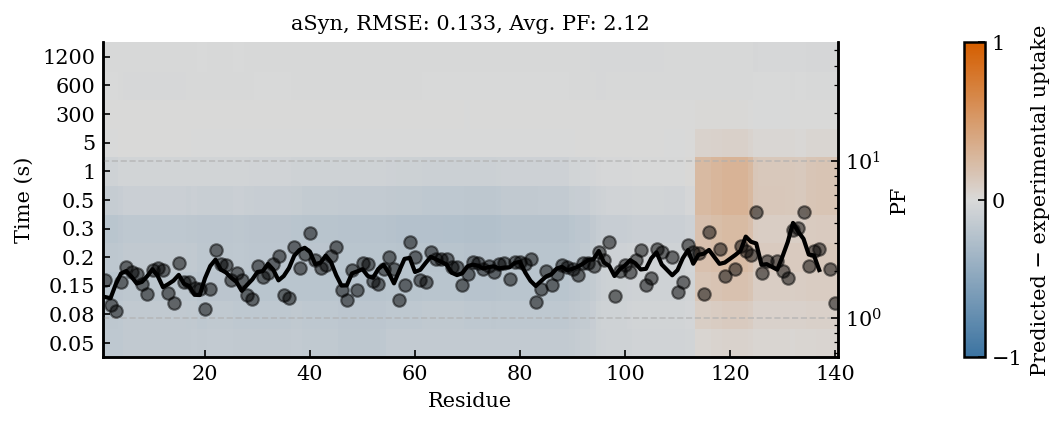

In [27]:
# plot posterior-experiment heatmap and PFs
from matplotlib.colors import LinearSegmentedColormap
protein = 'aSyn'

# ------------------------------------------------------------------
# Get posterior corresponding to automatically picked elbow
# ------------------------------------------------------------------

phi = data[protein]['phi']
rmse = data[protein]['rmse']
pred_array = np.array(data[protein]['pred_array'])

elidx = 0 # prior

# ------------------------------------------------------------------
# Experimental uptake + predicted - experimental difference
# pred_array is assumed to be in the same row order as the CSV
# ------------------------------------------------------------------

exp_uptake = pd.read_csv(f'../../EXP_DATA/{protein}.csv')
exp_uptake['Difference'] = pred_array[elidx] - exp_uptake['Rel. Uptake']

# colour scale: -1 -> 0 -> +1
cmap = LinearSegmentedColormap.from_list('difference_cmap', [(0.0, "#3B73A1"), (0.5, "#D9D9D9"), (1.0, "#D55E00")])

# ------------------------------------------------------------------
# Build residue x time matrix
# Each peptide contributes its predicted - experimental difference
# to every residue it covers.
# Overlapping peptides are averaged at each residue/time point.
# ------------------------------------------------------------------

times_s = np.sort(exp_uptake['Time (s)'].dropna().unique())
residues = np.arange(int(exp_uptake['Start'].min()), int(exp_uptake['End'].max()) + 1)

difference = np.full((len(times), len(residues)), np.nan)

for i, t in enumerate(times):
    df_t = exp_uptake[exp_uptake['Time (s)'] == t]
    for j, resi in enumerate(residues):
        vals = df_t.loc[(df_t['Start'] <= resi) & (df_t['End'] >= resi), 'Difference'].values
        if len(vals) > 0:
            difference[i, j] = np.nanmean(vals)

# ------------------------------------------------------------------
# Calculate posterior ensemble-averaged protection factors
# ------------------------------------------------------------------

res = np.loadtxt(f'../../DESRES_IDPs/{protein}/M14DH_scaled/amideresidues.txt').astype(int)
fopen = np.load(f'../../DESRES_IDPs/{protein}/M14DH_scaled/O.npy')

synframes = 0
wopt = data[protein]['wopt_array'][elidx]

PF_post = 1 / np.average(fopen, axis=0, weights=wopt[:len(wopt)-synframes])

# moving average
window_size = 3
kernel = np.ones(window_size) / window_size
PF_post_smooth = np.convolve(PF_post, kernel, mode='valid')
res_smooth = res[:len(PF_post_smooth)]

# ------------------------------------------------------------------
# Cell edges for pcolormesh
# ------------------------------------------------------------------

x_edges = np.arange(residues[0] - 0.5, residues[-1] + 1.5, 1)
y_edges = np.arange(len(times) + 1)

# ------------------------------------------------------------------
# Plot
# Keep heatmap itself the same width as in the original heatmap
# ------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 3))

im = ax.pcolormesh(x_edges, y_edges, difference, cmap=cmap, vmin=-1, vmax=1, shading='flat', rasterized=True)

ax.set_xlabel('Residue')
ax.set_ylabel('Time (s)')
ax.set_title(protein + str(f', RMSE: {rmse[elidx]:.3f}, Avg. PF: {np.mean(PF_post):.2f}'), fontsize=10)

ax.set_yticks(np.arange(len(times)) + 0.5)
ax.set_yticklabels([f'{t:g}' for t in times_s])

ax.tick_params(top=False, right=False)
ax.spines['top'].set_visible(False)

# ------------------------------------------------------------------
# Protection factors on right y-axis
# ------------------------------------------------------------------

ax2 = ax.twinx()

ax2.scatter(res, PF_post, color='black', alpha=0.5, zorder=20)
ax2.plot(res_smooth, PF_post_smooth, color='black', lw=2, zorder=21)

ax2.set_ylabel('PF')
ax2.set_yscale('log')
ax2.set_ylim(10**-0.25, 10**1.75)
ax2.tick_params(top=False)
ax2.spines['top'].set_visible(False)

# ------------------------------------------------------------------
# Match original heatmap plotting width and add colorbar outside it
# ------------------------------------------------------------------

plt.subplots_adjust(left=0.12, right=0.82, bottom=0.18, top=0.88)

cax = fig.add_axes([0.94, 0.18, 0.02, 0.70])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Predicted − experimental uptake')
cbar.set_ticks([-1, 0, 1])

plt.savefig(f'{protein}_DESRES_uptake_difference_heatmap_PF_prior.pdf', dpi=300, bbox_inches='tight')
plt.show()